# Exploratory Data Analysis on Superstore Retail Sales
**Datheon – Data Analytics & Power BI Internship · Task 1**

**Objective:** Wrangle the Superstore dataset, profile missing values, and uncover commercial patterns in purchase volume, monthly seasonality, category revenue and discount sensitivity, then formulate executive takeaways.

**Notebook outline**
1. Load data & first look
2. Data cleaning (missing values, dtypes, dates, duplicates)
3. Feature engineering (Year-Month, Profit Margin)
4. Aggregations by Category, Region, Segment
5. Visual analysis (monthly sales velocity, discount vs profit, etc.)
6. Executive takeaways (5 annotated business findings)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.options.display.float_format = "{:,.2f}".format

## 1. Load data & first look

In [2]:
# The file contains non-UTF8 characters, so latin1 encoding is used
raw = pd.read_csv("superstore_sales.csv", encoding="latin1")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [4]:
raw.tail(8)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observation:** the file does not end where the orders end. After the last real order (row 9,994) there are extra rows from *other lookup tables* that were pasted into the same CSV (a *Returned* list with "Yes" flags and a *People / Region manager* list). They are not sales records and would distort every count and sum, so they must be removed.

## 2. Data cleaning

### 2.1 Missing-value profiling (before cleaning)

In [5]:
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(raw) * 100).round(2)
missing[missing["missing_count"] > 0]

,missing_count,missing_%
Order Date,806,7.46
Ship Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Segment,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46
Postal Code,817,7.56


Almost every column has the same number of missing values (806) – a signature of **entirely empty/foreign rows**, not random gaps. `Postal Code` has 11 extra missing values – a *genuine* gap, checked below.

In [6]:
# 1) Remove the rows that are not orders (no Order Date) - the appended lookup tables
df = raw.dropna(subset=["Order Date"]).copy()
print(f"Removed {len(raw) - len(df):,} non-order rows -> {len(df):,} order lines remain")

# 2) Genuine missing values that remain
print("\nRemaining missing values:")
print(df.isna().sum()[lambda s: s > 0])
print("\nCities with missing Postal Code:", df.loc[df["Postal Code"].isna(), "City"].unique())

Removed 806 non-order rows -> 9,994 order lines remain

Remaining missing values:
Postal Code    11
dtype: int64

Cities with missing Postal Code: <ArrowStringArray>
['Burlington']
Length: 1, dtype: str


All 11 missing postal codes belong to **Burlington, Vermont** (the original data left them blank). Postal code is not used in any calculation, so I fill the known value (05401) and store it as a text field, since postal codes are identifiers, not numbers.

In [7]:
df.loc[df["Postal Code"].isna() & (df["City"] == "Burlington"), "Postal Code"] = 5401
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)
assert df.isna().sum().sum() == 0, "There are still missing values"
print("No missing values remain.")

No missing values remain.


### 2.2 Fix data types & parse dates

In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")
df["Row ID"]     = df["Row ID"].astype(int)
df["Quantity"]   = df["Quantity"].astype(int)

# strip stray whitespace in text columns
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()

df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

### 2.3 Integrity checks (duplicates, logic, ranges)

In [9]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate Row IDs    :", df["Row ID"].duplicated().sum())
print("Ship before order    :", (df["Ship Date"] < df["Order Date"]).sum())
print("Negative/zero sales  :", (df["Sales"] <= 0).sum())
print("Discount outside 0-1 :", (~df["Discount"].between(0, 1)).sum())
print("Date range           :", df["Order Date"].min().date(), "->", df["Order Date"].max().date())
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

Duplicate rows       : 0
Duplicate Row IDs    : 0
Ship before order    : 0
Negative/zero sales  : 0
Discount outside 0-1 : 0
Date range           : 2015-01-03 -> 2018-12-30


,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00"
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,"-6,599.98"
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,"22,638.48",14.00,0.80,"8,399.98"


The data is clean: no duplicates, no impossible dates, and all discounts are valid. `Profit` contains negatives (loss-making lines) – these are **real business signals**, not errors, so they are kept. `Sales` and `Profit` have a long right tail (a few very large orders), so medians are used alongside means where relevant.

## 3. Feature engineering

In [10]:
df["Year"]          = df["Order Date"].dt.year
df["Month"]         = df["Order Date"].dt.month
df["Year-Month"]    = df["Order Date"].dt.to_period("M")
df["Ship Days"]     = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin"] = df["Profit"] / df["Sales"]

# Discount bands used later for the discount-sensitivity analysis
bins   = [-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1.0]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

df.to_csv("superstore_clean.csv", index=False)   # cleaned dataset for Power BI (Task 2)
print("Clean shape:", df.shape)
df.head()

Clean shape: (9994, 27)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Year,Month,Year-Month,Ship Days,Profit Margin,Discount Band
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.96,2,0.00,41.91,2017,11,2017-11,3,0.16,0%
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.94,3,0.00,219.58,2017,11,2017-11,3,0.30,0%
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.62,2,0.00,6.87,2017,6,2017-06,4,0.47,0%
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.58,5,0.45,-383.03,2016,10,2016-10,7,-0.40,31-50%
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.37,2,0.20,2.52,2016,10,2016-10,7,0.11,11-20%


## 4. Headline KPIs

In [11]:
kpi = {
    "Total Sales":      df["Sales"].sum(),
    "Total Profit":     df["Profit"].sum(),
    "Overall Margin %": df["Profit"].sum() / df["Sales"].sum() * 100,
    "Orders":           df["Order ID"].nunique(),
    "Customers":        df["Customer ID"].nunique(),
    "Avg Order Value":  df.groupby("Order ID")["Sales"].sum().mean(),
}
pd.Series(kpi).to_frame("Value")

,Value
Total Sales,"2,297,200.86"
Total Profit,"286,397.02"
Overall Margin %,12.47
Orders,"5,009.00"
Customers,793.00
Avg Order Value,458.61


## 5. Aggregations: Category, Region, Segment

In [12]:
def summarize(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"),
                           Profit=("Profit", "sum"),
                           Orders=("Order ID", "nunique"),
                           Quantity=("Quantity", "sum"))
    g["Margin %"] = g["Profit"] / g["Sales"] * 100
    return g.sort_values("Sales", ascending=False)

by_cat = summarize("Category");  by_reg = summarize("Region");  by_seg = summarize("Segment")
display(by_cat); display(by_reg); display(by_seg)

,Sales,Profit,Orders,Quantity,Margin %
Category,,,,,
Technology,"836,154.03","145,454.95",1544,6939,17.40
Furniture,"741,999.80","18,451.27",1764,8028,2.49
Office Supplies,"719,047.03","122,490.80",3742,22906,17.04


,Sales,Profit,Orders,Quantity,Margin %
Region,,,,,
West,"725,457.82","108,418.45",1611,12266,14.94
East,"678,781.24","91,522.78",1401,10618,13.48
Central,"501,239.89","39,706.36",1175,8780,7.92
South,"391,721.91","46,749.43",822,6209,11.93


,Sales,Profit,Orders,Quantity,Margin %
Segment,,,,,
Consumer,"1,161,401.34","134,119.21",2586,19521,11.55
Corporate,"706,146.37","91,979.13",1514,11608,13.03
Home Office,"429,653.15","60,298.68",909,6744,14.03


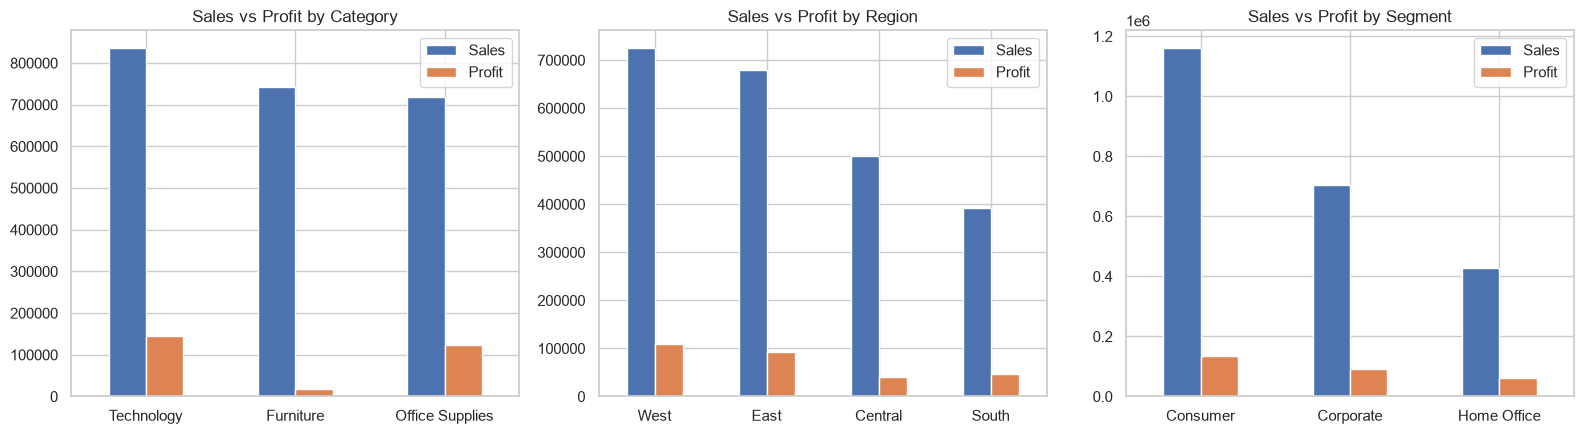

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (tbl, title) in zip(axes, [(by_cat, "Category"), (by_reg, "Region"), (by_seg, "Segment")]):
    tbl[["Sales", "Profit"]].plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"Sales vs Profit by {title}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

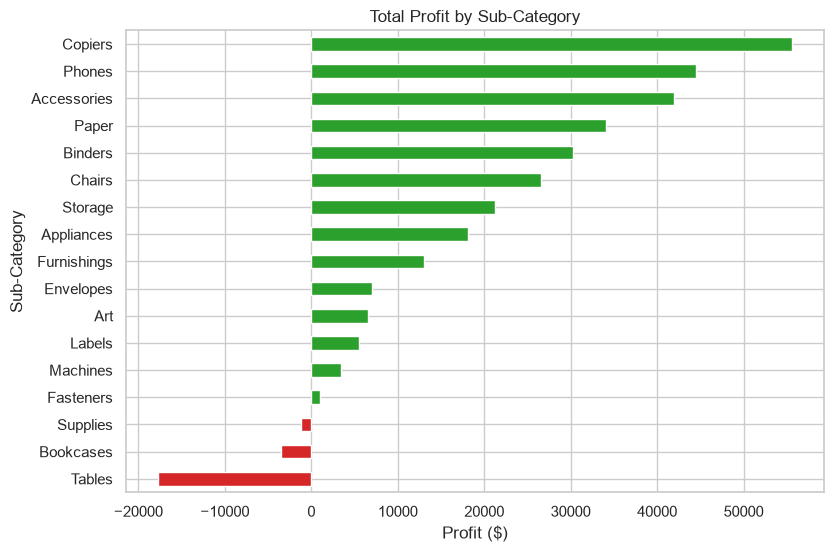

,Sales,Profit,Margin %
Sub-Category,,,
Tables,"206,965.53","-17,725.48",-8.56
Bookcases,"114,880.00","-3,472.56",-3.02
Supplies,"46,673.54","-1,189.10",-2.55
Fasteners,"3,024.28",949.52,31.40
Machines,"189,238.63","3,384.76",1.79


In [14]:
# Sub-category profitability: which products make or lose money?
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Profit")
colors = ["#d62728" if p < 0 else "#2ca02c" for p in sub["Profit"]]
ax = sub["Profit"].plot(kind="barh", color=colors, figsize=(9, 6))
ax.set_title("Total Profit by Sub-Category"); ax.set_xlabel("Profit ($)")
plt.show()
sub.assign(**{"Margin %": sub["Profit"] / sub["Sales"] * 100}).head(5)

### Combined grouping: Category x Region x Segment

Sales    Profit  Margin %
Category        Region  Segment                                  
Furniture       Central Consumer    86,229.22 -3,994.43     -4.63
                        Home Office 25,482.34 -1,198.61     -4.70
Office Supplies Central Corporate   41,137.70     99.29      0.24
Furniture       East    Corporate   64,209.05    342.13      0.53
                        Home Office 29,870.36    665.93      2.23

Sales    Profit  Margin %
Category        Region Segment                                 
Office Supplies West   Corporate  77,133.86 18,527.70     24.02
                East   Consumer  101,255.14 19,222.69     18.98
Technology      East   Consumer  135,441.23 19,930.18     14.72
Office Supplies West   Consumer  110,080.94 25,334.37     23.01
Technology      West   Consumer  132,991.75 27,785.57     20.89

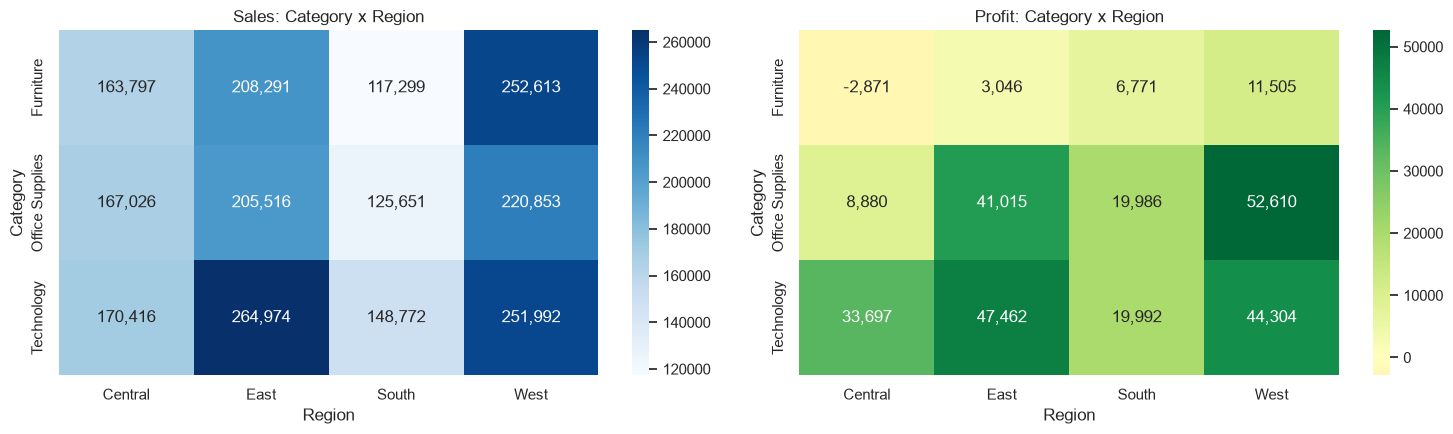

In [15]:
combo = (df.groupby(["Category", "Region", "Segment"])
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
           .assign(**{"Margin %": lambda x: x["Profit"] / x["Sales"] * 100}))
display(combo.sort_values("Profit").head(5))      # weakest combinations
display(combo.sort_values("Profit").tail(5))      # strongest combinations

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(df.pivot_table(index="Category", columns="Region", values="Sales", aggfunc="sum"),
            annot=True, fmt=",.0f", cmap="Blues", ax=axes[0]); axes[0].set_title("Sales: Category x Region")
sns.heatmap(df.pivot_table(index="Category", columns="Region", values="Profit", aggfunc="sum"),
            annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=axes[1]); axes[1].set_title("Profit: Category x Region")
plt.tight_layout(); plt.show()

## 6. Monthly seasonality & sales velocity

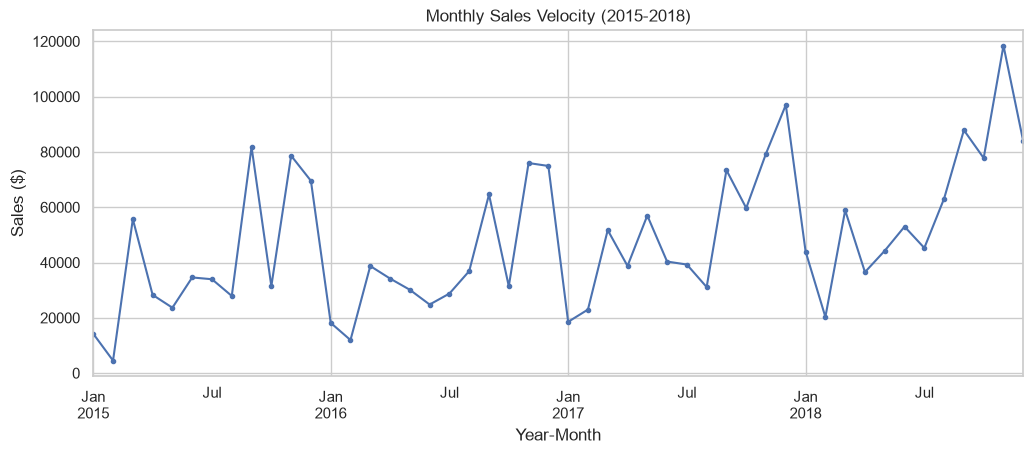

In [16]:
monthly = df.groupby("Year-Month")["Sales"].sum()
ax = monthly.plot(figsize=(12, 4.5), marker="o", markersize=3)
ax.set_title("Monthly Sales Velocity (2015-2018)"); ax.set_ylabel("Sales ($)")
plt.show()

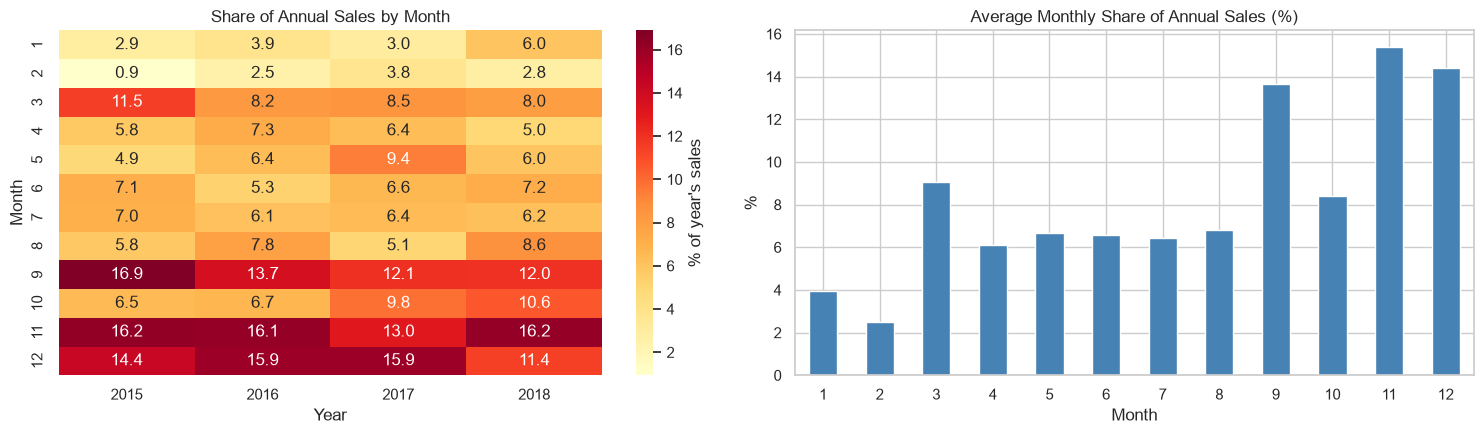

Sep-Dec share of annual sales by year (%):
Year
2015   54.00
2016   52.50
2017   50.80
2018   50.20


In [17]:
# Seasonality: average share of annual sales by calendar month
pivot = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
share = pivot / pivot.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(share, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "% of year's sales"})
axes[0].set_title("Share of Annual Sales by Month")
share.mean(axis=1).plot(kind="bar", ax=axes[1], rot=0, color="steelblue")
axes[1].set_title("Average Monthly Share of Annual Sales (%)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

q4 = share.loc[[9, 10, 11, 12]].sum()
print("Sep-Dec share of annual sales by year (%):"); print(q4.round(1).to_string())

In [18]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Sales Growth %"]  = yearly["Sales"].pct_change() * 100
yearly["Profit Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly

,Sales,Profit,Sales Growth %,Profit Margin %
Year,,,,
2015,"484,247.50","49,543.97",NaN,10.23
2016,"470,532.51","61,618.60",-2.83,13.10
2017,"609,205.60","81,795.17",29.47,13.43
2018,"733,215.26","93,439.27",20.36,12.74


## 7. Discount sensitivity

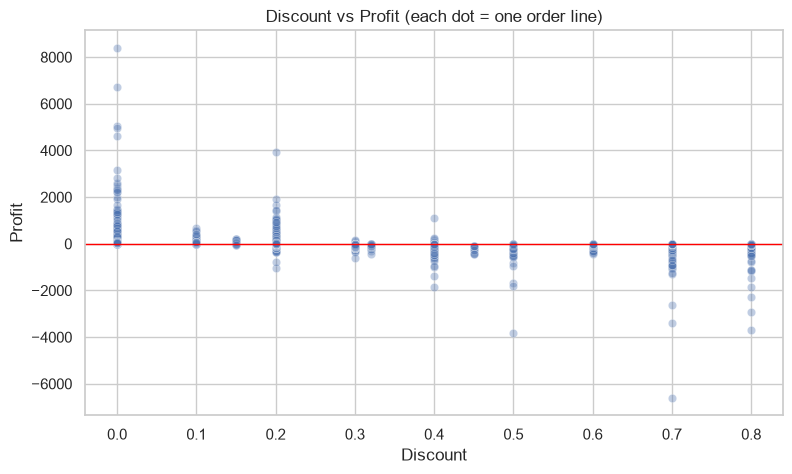

Correlation (Discount, Profit): -0.219


In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35, ax=ax)
ax.axhline(0, color="red", lw=1)
ax.set_title("Discount vs Profit (each dot = one order line)")
plt.show()
print("Correlation (Discount, Profit):", round(df["Discount"].corr(df["Profit"]), 3))

,Lines,Sales,Profit,Margin %,% Lines Loss-making
Discount Band,,,,,
0%,4798,"1,087,908.47","320,987.60",29.51,0.00
1-10%,94,"54,369.35","9,029.18",16.61,4.26
11-20%,3709,"792,152.89","91,756.30",11.58,13.99
21-30%,227,"103,226.65","-10,369.28",-10.05,91.63
31-50%,310,"195,314.76","-48,447.73",-24.80,91.61
>50%,856,"64,228.74","-76,559.05",-119.20,100.00


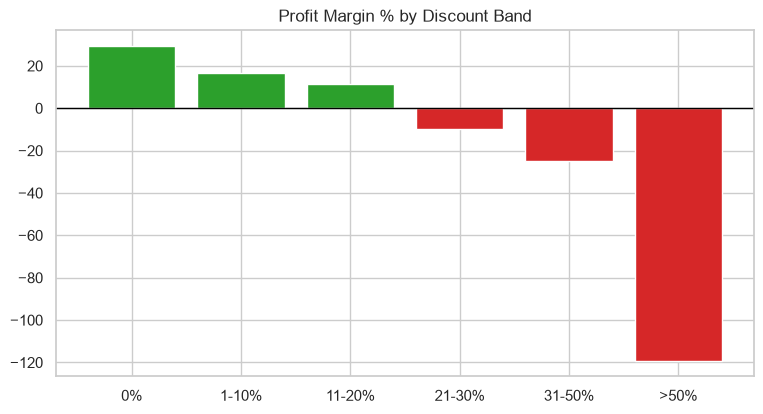

In [20]:
disc = df.groupby("Discount Band", observed=True).agg(
    Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin %"] = disc["Profit"] / disc["Sales"] * 100
disc["% Lines Loss-making"] = df.groupby("Discount Band", observed=True)["Profit"].apply(lambda s: (s < 0).mean() * 100)
display(disc)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(disc.index.astype(str), disc["Margin %"],
       color=["#d62728" if m < 0 else "#2ca02c" for m in disc["Margin %"]])
ax.axhline(0, color="black", lw=1); ax.set_title("Profit Margin % by Discount Band")
plt.show()

In [21]:
# Where are the losses concentrated?  (Category x Discount) and worst states
print(df.pivot_table(index="Category", columns="Discount Band", values="Profit", aggfunc="sum", observed=True).round(0))
print("\nWorst 5 states by profit:")
print(df.groupby("State")["Profit"].sum().sort_values().head(5).round(0))

Discount Band           0%    1-10%    11-20%     21-30%     31-50%       >50%
Category                                                                      
Furniture        58,133.00 7,111.00  7,685.00 -10,695.00 -33,943.00  -9,840.00
Office Supplies 130,506.00 1,086.00 38,039.00        NaN        NaN -47,140.00
Technology      132,348.00   832.00 46,033.00     326.00 -14,505.00 -19,579.00

Worst 5 states by profit:
State
Texas            -25,729.00
Ohio             -16,971.00
Pennsylvania     -15,560.00
Illinois         -12,608.00
North Carolina    -7,491.00
Name: Profit, dtype: float64


## 8. Customer purchase volume

Top 20% of customers generate 48.0% of sales
Average orders per customer: 6.3


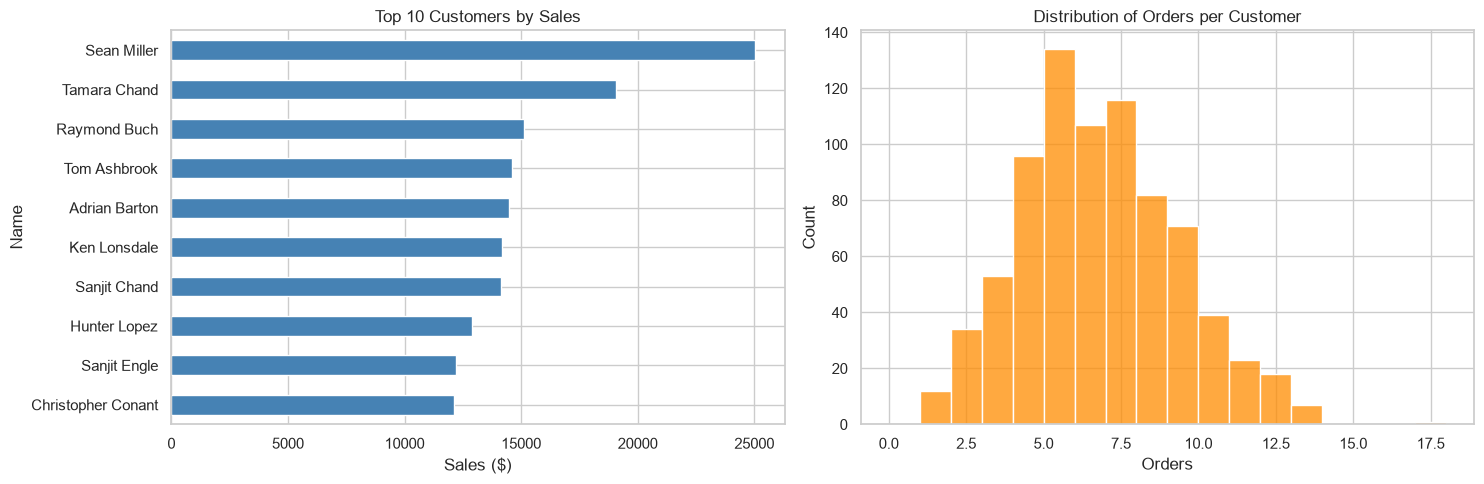

,Name,Sales,Profit,Orders
Customer ID,,,,
SM-20320,Sean Miller,"25,043.05","-1,980.74",5
TC-20980,Tamara Chand,"19,052.22","8,981.32",5
RB-19360,Raymond Buch,"15,117.34","6,976.10",6
TA-21385,Tom Ashbrook,"14,595.62","4,703.79",4
AB-10105,Adrian Barton,"14,473.57","5,444.81",10
KL-16645,Ken Lonsdale,"14,175.23",806.86,12
SC-20095,Sanjit Chand,"14,142.33","5,757.41",9
HL-15040,Hunter Lopez,"12,873.30","5,622.43",6
SE-20110,Sanjit Engle,"12,209.44","2,650.68",11


In [22]:
cust = df.groupby("Customer ID").agg(Name=("Customer Name", "first"),
                                     Sales=("Sales", "sum"),
                                     Profit=("Profit", "sum"),
                                     Orders=("Order ID", "nunique")).sort_values("Sales", ascending=False)

top20 = cust.head(int(len(cust) * 0.2))["Sales"].sum() / cust["Sales"].sum() * 100
print(f"Top 20% of customers generate {top20:.1f}% of sales")
print(f"Average orders per customer: {cust['Orders'].mean():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cust.head(10).set_index("Name")["Sales"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Customers by Sales"); axes[0].set_xlabel("Sales ($)")
sns.histplot(cust["Orders"], bins=range(0, int(cust["Orders"].max()) + 2), ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of Orders per Customer"); axes[1].set_xlabel("Orders")
plt.tight_layout(); plt.show()
cust.head(10)

## 9. Executive Takeaways (5 annotated business findings)

> Figures below were computed from the cleaned data (9,994 order lines, Jan 2015 – Dec 2018). Re-run the cells above to reproduce them.

**1. Heavy discounts destroy profit – the single biggest lever.**
Order lines with **no discount earn a ~29.5% margin**, 11-20% discounts earn ~11.6%, but lines discounted **over 20% are loss-making**: -10% (21-30%), -25% (31-50%) and **-119% above 50%**. Roughly 97% of lines discounted 30% or more lose money, and the correlation between discount and profit is negative (≈ -0.22). *Recommendation:* cap discounts at about 20% and require approval for anything higher.

**2. Furniture grows revenue but earns almost no profit.**
Furniture brings in $742K of sales but only **$18K profit (2.5% margin)**, versus ~17% for both Technology and Office Supplies. The cause is **Tables (-$17.7K) and Bookcases (-$3.5K)**, which both lose money overall. *Recommendation:* review pricing and discounting on Tables and Bookcases or reduce their promotion.

**3. Sales are strongly seasonal – Q4 (and September) carries the year.**
November and December are the largest months (~15% and ~14% of annual sales) and **September–December together deliver about 52% of yearly revenue**, while January and February are the weakest (≈4% and ≈3%). *Recommendation:* build inventory and staffing ahead of September, and use Q1 for targeted promotions to smooth demand.

**4. Business is growing and profitable overall, but the Central region lags.**
Sales rose from $484K (2015) to **$733K (2018)**, with total profit of ~$286K (12.5% margin). The **West (14.9%) and East (13.5%)** lead on margin, while the **Central region earns only 7.9%**, and states such as **Texas (-$25.7K), Ohio (-$17.0K) and Pennsylvania (-$15.6K)** lose money, which are likely discount-driven. *Recommendation:* audit pricing and discount policy in the Central region and the loss-making states.

**5. Technology and Office Supplies are the profit engines; Consumers are the volume, Home Office the margin.**
Technology (Copiers, Phones, Accessories) is the top-selling category and generates the most profit ($145K). The **Consumer segment** provides ~50% of revenue, but **Home Office (14.0%) and Corporate (13.0%)** earn better margins than Consumer (11.5%). Sales are also fairly concentrated: the top 20% of customers account for about 48% of sales. *Recommendation:* protect and grow Technology sales, and run loyalty / upsell programs aimed at the top customers and at higher-margin Corporate and Home Office segments.